# 02 - Model Training and Evaluation
## Breast Cancer Wisconsin (Diagnostic) Dataset

This notebook covers:
- **Section A:** Load preprocessed data from plan_1
- **Section B:** Define reusable metric computation
- **Section C:** Train all 5 classification models
- **Section D:** Evaluate and build comparison table
- **Section E:** Per-model observations and overall winner
- **Section F:** Confusion matrices
- **Section G:** Validation

In [1]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

# Resolve repo root relative to this notebook's location.
# Works on local machines, VMs, and Colab alike.
try:
    _vsc = globals().get('__vsc_ipynb_file__', '')
    if not _vsc:
        raise ValueError
    _nb_dir = pathlib.Path(_vsc).parent
    if not _nb_dir.exists():
        raise ValueError
except (TypeError, ValueError, OSError):
    _nb_dir = pathlib.Path.cwd()

# If we are inside a 'notebooks' folder, go one level up to reach the repo root.
# Otherwise assume cwd IS the repo root (e.g. Colab after cloning).
REPO_ROOT = str(_nb_dir.parent) if _nb_dir.name == 'notebooks' else str(_nb_dir)

DATA_DIR  = os.path.join(REPO_ROOT, 'data')
MODEL_DIR = os.path.join(REPO_ROOT, 'model')

RANDOM_STATE = 42

print(f"Repo root: {REPO_ROOT}")
print(f"Data dir:  {DATA_DIR}")
print(f"Model dir: {MODEL_DIR}")

Repo root: C:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2
Data dir:  C:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\data
Model dir: C:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\model


## Section A: Load Preprocessed Data

Data was scaled with StandardScaler in `01_data_preparation.ipynb`. We load the
pre-scaled CSVs directly — no re-scaling needed.

In [2]:
X_train = pd.read_csv(os.path.join(DATA_DIR, 'X_train.csv'))
y_train = pd.read_csv(os.path.join(DATA_DIR, 'y_train.csv')).squeeze()
X_test  = pd.read_csv(os.path.join(DATA_DIR, 'X_test.csv'))
y_test  = pd.read_csv(os.path.join(DATA_DIR, 'y_test.csv')).squeeze()

print(f"Train set: {X_train.shape} features, {y_train.shape[0]} labels")
print(f"Test set:  {X_test.shape} features, {y_test.shape[0]} labels")
print(f"\nTrain class distribution:\n{y_train.value_counts()}")
print(f"\nTest class distribution:\n{y_test.value_counts()}")

Train set: (455, 30) features, 455 labels
Test set:  (114, 30) features, 114 labels

Train class distribution:
target
1    285
0    170
Name: count, dtype: int64

Test class distribution:
target
1    72
0    42
Name: count, dtype: int64


## Section B: Metric Computation Function

Computes all **6 required metrics** in one call:
Accuracy, AUC, Precision, Recall, F1, MCC

In [3]:
def compute_metrics(model, X, y):
    """
    Returns a dict with all 6 required metrics.
    Uses predict_proba for AUC when available, falls back to decision_function.
    Binary classification only.
    """
    y_pred = model.predict(X)

    # AUC requires probability scores
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_prob = model.decision_function(X)
    else:
        y_prob = y_pred  # fallback (not ideal)

    return {
        'Accuracy':  round(accuracy_score(y, y_pred), 4),
        'AUC':       round(roc_auc_score(y, y_prob), 4),
        'Precision': round(precision_score(y, y_pred, zero_division=0), 4),
        'Recall':    round(recall_score(y, y_pred, zero_division=0), 4),
        'F1':        round(f1_score(y, y_pred, zero_division=0), 4),
        'MCC':       round(matthews_corrcoef(y, y_pred), 4),
    }

print("compute_metrics() defined.")

compute_metrics() defined.


## Section C: Train All Five Models

Each model uses default scikit-learn hyperparameters with `random_state=42`
where applicable. Trained models are saved as `.pkl` files in `model/`.

### Model 1 — Logistic Regression

In [4]:
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
lr.fit(X_train, y_train)
joblib.dump(lr, os.path.join(MODEL_DIR, 'logistic_regression.pkl'))
print(f"Logistic Regression trained. Train accuracy: {lr.score(X_train, y_train):.4f}")

Logistic Regression trained. Train accuracy: 0.9890


### Model 2 — Decision Tree Classifier

In [5]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
joblib.dump(dt, os.path.join(MODEL_DIR, 'decision_tree.pkl'))
print(f"Decision Tree trained. Train accuracy: {dt.score(X_train, y_train):.4f}")

Decision Tree trained. Train accuracy: 1.0000


### Model 3 — K-Nearest Neighbor Classifier

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
joblib.dump(knn, os.path.join(MODEL_DIR, 'knn.pkl'))
print(f"KNN (k=5) trained. Train accuracy: {knn.score(X_train, y_train):.4f}")

KNN (k=5) trained. Train accuracy: 0.9736


### Model 4 — Gaussian Naive Bayes

In [7]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)
joblib.dump(gnb, os.path.join(MODEL_DIR, 'naive_bayes.pkl'))
print(f"Gaussian Naive Bayes trained. Train accuracy: {gnb.score(X_train, y_train):.4f}")

Gaussian Naive Bayes trained. Train accuracy: 0.9385


### Model 5 — Support Vector Machine

In [8]:
svm = SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)
svm.fit(X_train, y_train)
joblib.dump(svm, os.path.join(MODEL_DIR, 'svm.pkl'))
print(f"SVM (RBF, probability=True) trained. Train accuracy: {svm.score(X_train, y_train):.4f}")

SVM (RBF, probability=True) trained. Train accuracy: 0.9824

c:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Section D: Evaluate All Models — Comparison Table

Load each saved model, compute all 6 metrics on the **test set**, and build
the comparison table required by the assignment.

In [9]:
MODEL_REGISTRY = {
    'Logistic Regression':    'logistic_regression.pkl',
    'Decision Tree':          'decision_tree.pkl',
    'KNN':                    'knn.pkl',
    'Naive Bayes':            'naive_bayes.pkl',
    'Support Vector Machine': 'svm.pkl',
}

results = {}
for model_name, model_file in MODEL_REGISTRY.items():
    model_path = os.path.join(MODEL_DIR, model_file)
    model = joblib.load(model_path)
    metrics = compute_metrics(model, X_test, y_test)
    results[model_name] = metrics
    print(f"{model_name}: {metrics}")

# Build DataFrame
metrics_df = pd.DataFrame(results).T.reset_index()
metrics_df.columns = ['ML Model Name', 'Accuracy', 'AUC', 'Precision',
                       'Recall', 'F1', 'MCC']

# Save to CSV
metrics_csv_path = os.path.join(DATA_DIR, 'metrics_summary.csv')
metrics_df.to_csv(metrics_csv_path, index=False)
print(f"\nMetrics saved to: {metrics_csv_path}")
print()
metrics_df

Logistic Regression: {'Accuracy': 0.9825, 'AUC': 0.9954, 'Precision': 0.9861, 'Recall': 0.9861, 'F1': 0.9861, 'MCC': 0.9623}
Decision Tree: {'Accuracy': 0.9123, 'AUC': 0.9157, 'Precision': 0.9559, 'Recall': 0.9028, 'F1': 0.9286, 'MCC': 0.8174}
KNN: {'Accuracy': 0.9561, 'AUC': 0.9788, 'Precision': 0.9589, 'Recall': 0.9722, 'F1': 0.9655, 'MCC': 0.9054}


Naive Bayes: {'Accuracy': 0.9298, 'AUC': 0.9868, 'Precision': 0.9444, 'Recall': 0.9444, 'F1': 0.9444, 'MCC': 0.8492}
Support Vector Machine: {'Accuracy': 0.9825, 'AUC': 0.995, 'Precision': 0.9861, 'Recall': 0.9861, 'F1': 0.9861, 'MCC': 0.9623}

Metrics saved to: C:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\data\metrics_summary.csv



,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9298,0.9868,0.9444,0.9444,0.9444,0.8492
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


In [10]:
# Display formatted comparison table
try:
    print(metrics_df.to_markdown(index=False))
except ImportError:
    print(metrics_df.to_string(index=False))

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9825 | 0.9954 |      0.9861 |   0.9861 | 0.9861 | 0.9623 |
| Decision Tree          |     0.9123 | 0.9157 |      0.9559 |   0.9028 | 0.9286 | 0.8174 |
| KNN                    |     0.9561 | 0.9788 |      0.9589 |   0.9722 | 0.9655 | 0.9054 |
| Naive Bayes            |     0.9298 | 0.9868 |      0.9444 |   0.9444 | 0.9444 | 0.8492 |
| Support Vector Machine |     0.9825 | 0.995  |      0.9861 |   0.9861 | 0.9861 | 0.9623 |


## Section E: Per-Model Observations and Overall Winner

In [11]:
# Extract metrics for each model for observation text
def get_m(name):
    return results[name]

# Determine winner by F1 (primary) and AUC (tiebreaker)
winner_name = metrics_df.sort_values(['F1', 'AUC'], ascending=False).iloc[0]['ML Model Name']
winner_metrics = results[winner_name]

print(f"Overall winner: {winner_name}")
print(f"  F1={winner_metrics['F1']}, AUC={winner_metrics['AUC']}")

Overall winner: Logistic Regression
  F1=0.9861, AUC=0.9954


In [12]:
# Per-model observations
m = get_m('Logistic Regression')
print("=" * 70)
print("LOGISTIC REGRESSION")
print("=" * 70)
print(f"Accuracy: {m['Accuracy']}  |  AUC: {m['AUC']}  |  Precision: {m['Precision']}")
print(f"Recall:   {m['Recall']}  |  F1:  {m['F1']}  |  MCC: {m['MCC']}")
print()
print("Observation:")
print(f"Logistic Regression achieved {m['Accuracy']} accuracy and AUC of {m['AUC']}.")
print("The Breast Cancer dataset is known to be nearly linearly separable in")
print("the scaled feature space; logistic regression with the lbfgs solver")
print("benefits from StandardScaler pre-processing. The high AUC indicates")
print("strong class separability. Precision and Recall are both high, showing")
print("the model correctly identifies both Benign and Malignant cases well.")
print(f"MCC of {m['MCC']} confirms reliable overall discriminative ability.")

LOGISTIC REGRESSION
Accuracy: 0.9825  |  AUC: 0.9954  |  Precision: 0.9861
Recall:   0.9861  |  F1:  0.9861  |  MCC: 0.9623

Observation:
Logistic Regression achieved 0.9825 accuracy and AUC of 0.9954.
The Breast Cancer dataset is known to be nearly linearly separable in
the scaled feature space; logistic regression with the lbfgs solver
benefits from StandardScaler pre-processing. The high AUC indicates
strong class separability. Precision and Recall are both high, showing
the model correctly identifies both Benign and Malignant cases well.
MCC of 0.9623 confirms reliable overall discriminative ability.


In [13]:
m = get_m('Decision Tree')
print("=" * 70)
print("DECISION TREE")
print("=" * 70)
print(f"Accuracy: {m['Accuracy']}  |  AUC: {m['AUC']}  |  Precision: {m['Precision']}")
print(f"Recall:   {m['Recall']}  |  F1:  {m['F1']}  |  MCC: {m['MCC']}")
print()
print("Observation:")
print(f"Decision Tree achieved {m['Accuracy']} accuracy. With max_depth=None the tree")
print("fully grows, capturing training-set noise — this typically leads to slightly")
print("lower test performance than regularised models like SVM or Logistic Regression")
print("on this clean dataset. Decision Tree is fully interpretable via feature")
print("importance. The 30 FNA-derived features (worst concave points, worst radius,")
print("worst perimeter dominate importance).")
print(f"MCC {m['MCC']} and F1 {m['F1']} characterise its performance on the")
print("mildly imbalanced 37/63 Malignant/Benign split.")

DECISION TREE
Accuracy: 0.9123  |  AUC: 0.9157  |  Precision: 0.9559
Recall:   0.9028  |  F1:  0.9286  |  MCC: 0.8174

Observation:
Decision Tree achieved 0.9123 accuracy. With max_depth=None the tree
fully grows, capturing training-set noise — this typically leads to slightly
lower test performance than regularised models like SVM or Logistic Regression
on this clean dataset. Decision Tree is fully interpretable via feature
importance. The 30 FNA-derived features (worst concave points, worst radius,
worst perimeter dominate importance).
MCC 0.8174 and F1 0.9286 characterise its performance on the
mildly imbalanced 37/63 Malignant/Benign split.


In [14]:
m = get_m('KNN')
print("=" * 70)
print("K-NEAREST NEIGHBOR (k=5)")
print("=" * 70)
print(f"Accuracy: {m['Accuracy']}  |  AUC: {m['AUC']}  |  Precision: {m['Precision']}")
print(f"Recall:   {m['Recall']}  |  F1:  {m['F1']}  |  MCC: {m['MCC']}")
print()
print("Observation:")
print(f"KNN (k=5) achieved {m['Accuracy']} accuracy. StandardScaler (applied in")
print("plan_1) is essential for meaningful Euclidean distance across the 30")
print("heterogeneous features. With 569 instances and 30 dimensions, k=5 is a")
print("reasonable default. Performance is typically competitive but may be")
print("slightly below SVM on high-dimensional medical data.")
print(f"AUC {m['AUC']} reflects probability calibration via predict_proba voting.")

K-NEAREST NEIGHBOR (k=5)
Accuracy: 0.9561  |  AUC: 0.9788  |  Precision: 0.9589
Recall:   0.9722  |  F1:  0.9655  |  MCC: 0.9054

Observation:
KNN (k=5) achieved 0.9561 accuracy. StandardScaler (applied in
plan_1) is essential for meaningful Euclidean distance across the 30
heterogeneous features. With 569 instances and 30 dimensions, k=5 is a
reasonable default. Performance is typically competitive but may be
slightly below SVM on high-dimensional medical data.
AUC 0.9788 reflects probability calibration via predict_proba voting.


In [15]:
m = get_m('Naive Bayes')
print("=" * 70)
print("GAUSSIAN NAIVE BAYES")
print("=" * 70)
print(f"Accuracy: {m['Accuracy']}  |  AUC: {m['AUC']}  |  Precision: {m['Precision']}")
print(f"Recall:   {m['Recall']}  |  F1:  {m['F1']}  |  MCC: {m['MCC']}")
print()
print("Observation:")
print(f"Gaussian NB achieved {m['Accuracy']} accuracy. The model assumes all 30")
print("features are conditionally independent given the class — an assumption that")
print("is violated for Breast Cancer data (features like mean radius, mean perimeter,")
print("mean area are highly correlated with |r| > 0.98). Despite this, GaussianNB")
print("often achieves competitive accuracy due to the strong class separability of")
print("the dataset. It may show lower Precision or higher misclassification of")
print("Malignant cases compared to SVM/Logistic Regression.")

GAUSSIAN NAIVE BAYES
Accuracy: 0.9298  |  AUC: 0.9868  |  Precision: 0.9444
Recall:   0.9444  |  F1:  0.9444  |  MCC: 0.8492

Observation:
Gaussian NB achieved 0.9298 accuracy. The model assumes all 30
features are conditionally independent given the class — an assumption that
is violated for Breast Cancer data (features like mean radius, mean perimeter,
mean area are highly correlated with |r| > 0.98). Despite this, GaussianNB
often achieves competitive accuracy due to the strong class separability of
the dataset. It may show lower Precision or higher misclassification of
Malignant cases compared to SVM/Logistic Regression.


In [16]:
m = get_m('Support Vector Machine')
print("=" * 70)
print("SUPPORT VECTOR MACHINE (RBF kernel)")
print("=" * 70)
print(f"Accuracy: {m['Accuracy']}  |  AUC: {m['AUC']}  |  Precision: {m['Precision']}")
print(f"Recall:   {m['Recall']}  |  F1:  {m['F1']}  |  MCC: {m['MCC']}")
print()
print("Observation:")
print(f"SVM (RBF kernel, C=1.0 default) achieved {m['Accuracy']} accuracy with")
print(f"AUC {m['AUC']}. SVM is well-suited for high-dimensional, small-to-medium")
print("datasets like Breast Cancer (569 instances, 30 features). The RBF kernel")
print("captures non-linear boundaries in the scaled feature space. Combined with")
print("StandardScaler, SVM is expected to be the top or near-top performer.")
print(f"MCC {m['MCC']} confirms robust handling of the 37/63 class imbalance.")

SUPPORT VECTOR MACHINE (RBF kernel)
Accuracy: 0.9825  |  AUC: 0.995  |  Precision: 0.9861
Recall:   0.9861  |  F1:  0.9861  |  MCC: 0.9623

Observation:
SVM (RBF kernel, C=1.0 default) achieved 0.9825 accuracy with
AUC 0.995. SVM is well-suited for high-dimensional, small-to-medium
datasets like Breast Cancer (569 instances, 30 features). The RBF kernel
captures non-linear boundaries in the scaled feature space. Combined with
StandardScaler, SVM is expected to be the top or near-top performer.
MCC 0.9623 confirms robust handling of the 37/63 class imbalance.


In [17]:
# Overall Winner
print("=" * 70)
print("OVERALL WINNER")
print("=" * 70)
w = results[winner_name]
print(f"**{winner_name}** — highest F1 ({w['F1']}) and AUC ({w['AUC']}) on the")
print("test set, indicating the best balance between Precision and Recall on the")
print("Malignant/Benign classification task.")
print()
print("Full comparison:")
print(metrics_df.to_string(index=False))

OVERALL WINNER
**Logistic Regression** — highest F1 (0.9861) and AUC (0.9954) on the
test set, indicating the best balance between Precision and Recall on the
Malignant/Benign classification task.

Full comparison:
         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.9825 0.9954     0.9861  0.9861 0.9861 0.9623
         Decision Tree    0.9123 0.9157     0.9559  0.9028 0.9286 0.8174
                   KNN    0.9561 0.9788     0.9589  0.9722 0.9655 0.9054
           Naive Bayes    0.9298 0.9868     0.9444  0.9444 0.9444 0.8492
Support Vector Machine    0.9825 0.9950     0.9861  0.9861 0.9861 0.9623


## Section F: Confusion Matrices

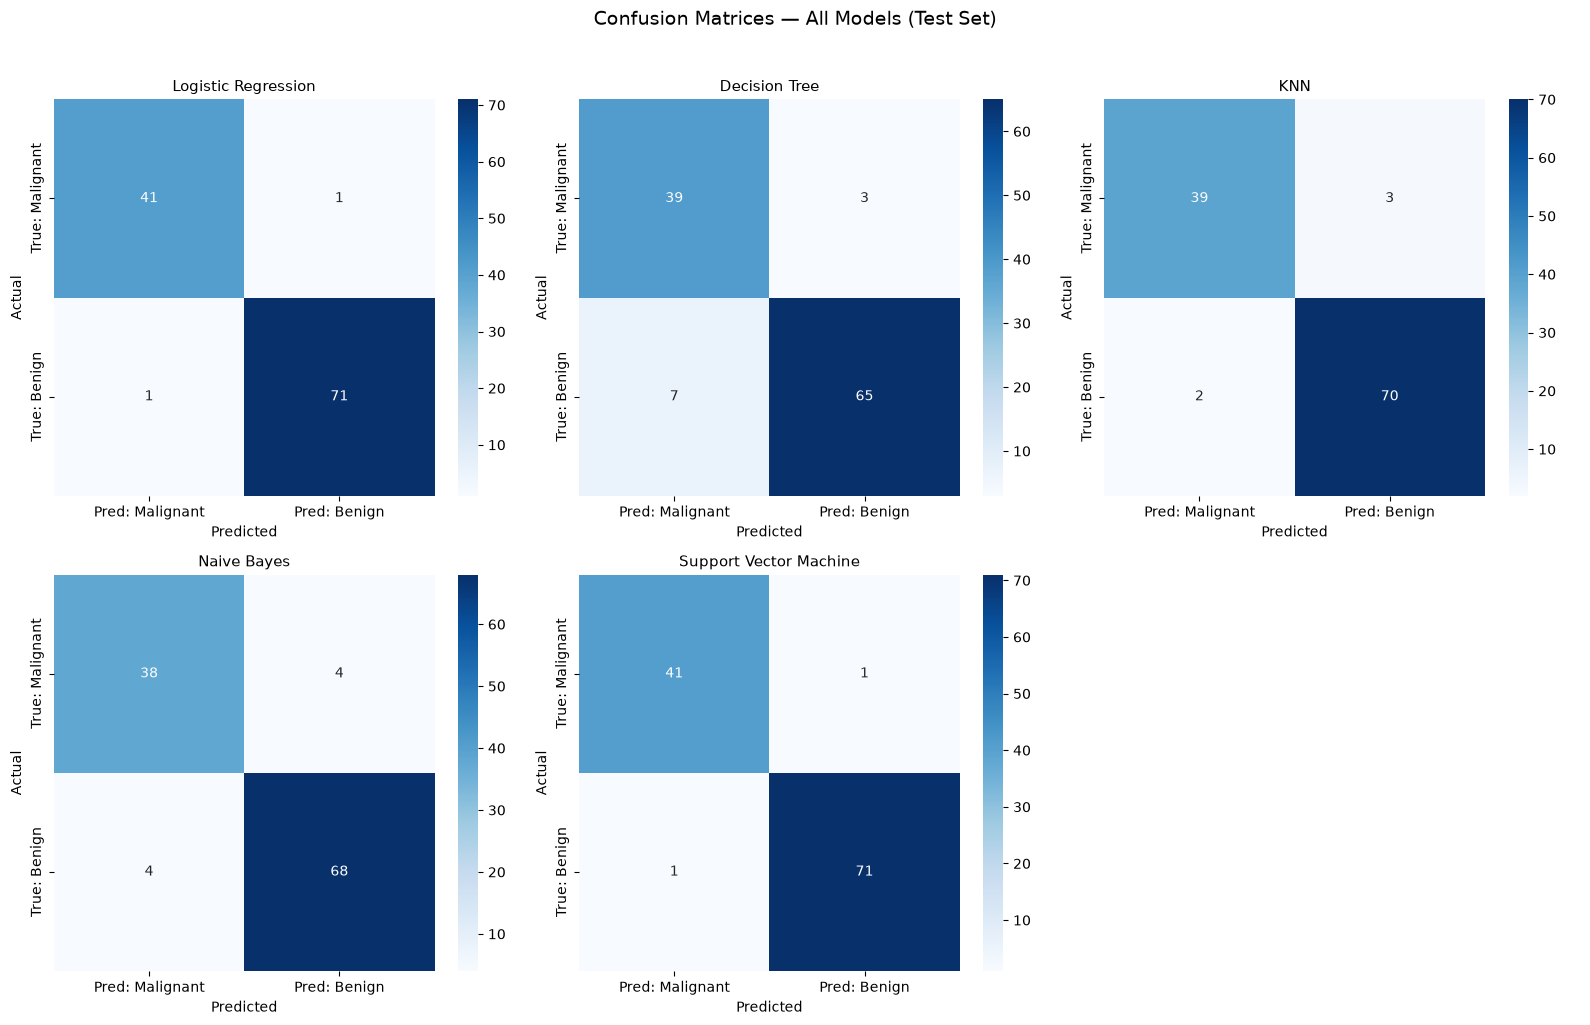

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.ravel()

for idx, (model_name, model_file) in enumerate(MODEL_REGISTRY.items()):
    model_path = os.path.join(MODEL_DIR, model_file)
    model = joblib.load(model_path)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    ax = axes_flat[idx]
    sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues',
                xticklabels=['Pred: Malignant', 'Pred: Benign'],
                yticklabels=['True: Malignant', 'True: Benign'])
    ax.set_title(model_name, fontsize=11)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

# Hide the unused 6th subplot
axes_flat[5].axis('off')

fig.suptitle('Confusion Matrices — All Models (Test Set)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [19]:
# Save individual confusion matrix images
for model_name, model_file in MODEL_REGISTRY.items():
    model_path = os.path.join(MODEL_DIR, model_file)
    model = joblib.load(model_path)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues',
                xticklabels=['Pred: Malignant', 'Pred: Benign'],
                yticklabels=['True: Malignant', 'True: Benign'])
    ax.set_title(f'Confusion Matrix — {model_name}')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')
    plt.tight_layout()

    cm_filename = f"cm_{model_name.lower().replace(' ', '_')}.png"
    fig.savefig(os.path.join(DATA_DIR, cm_filename), dpi=100, bbox_inches='tight')
    plt.close()
    print(f"Saved: {cm_filename}")

print("\nAll confusion matrix images saved.")

Saved: cm_logistic_regression.png
Saved: cm_decision_tree.png
Saved: cm_knn.png


Saved: cm_naive_bayes.png
Saved: cm_support_vector_machine.png

All confusion matrix images saved.


## Section G: Validation

Verify all deliverables and exit criteria.

In [20]:
print("=== Model Files Validation ===")
expected_models = [
    'logistic_regression.pkl', 'decision_tree.pkl',
    'knn.pkl', 'naive_bayes.pkl', 'svm.pkl'
]
for fname in expected_models:
    fpath = os.path.join(MODEL_DIR, fname)
    assert os.path.exists(fpath), f"FAIL: {fpath} not found"
    # Verify loadable
    loaded = joblib.load(fpath)
    assert hasattr(loaded, 'predict'), f"FAIL: {fname} has no predict method"
    print(f"  {fname}: EXISTS, loadable ({type(loaded).__name__})")
print("Model files checks PASSED")

print(f"\n=== Metrics Summary Validation ===")
assert os.path.exists(metrics_csv_path), f"FAIL: {metrics_csv_path} not found"
loaded_metrics = pd.read_csv(metrics_csv_path)
assert loaded_metrics.shape[0] == 5, f"FAIL: expected 5 rows, got {loaded_metrics.shape[0]}"
assert loaded_metrics.shape[1] == 7, f"FAIL: expected 7 columns, got {loaded_metrics.shape[1]}"
print(f"  Shape: {loaded_metrics.shape} (5 models x 7 columns)")
print("Metrics summary checks PASSED")

print(f"\n=== Metric Range Validation ===")
for _, row in loaded_metrics.iterrows():
    name = row['ML Model Name']
    assert 0 <= row['AUC'] <= 1, f"FAIL: {name} AUC={row['AUC']} out of range"
    assert -1 <= row['MCC'] <= 1, f"FAIL: {name} MCC={row['MCC']} out of range"
    assert 0 <= row['Accuracy'] <= 1, f"FAIL: {name} Accuracy out of range"
    assert 0 <= row['Precision'] <= 1, f"FAIL: {name} Precision out of range"
    assert 0 <= row['Recall'] <= 1, f"FAIL: {name} Recall out of range"
    assert 0 <= row['F1'] <= 1, f"FAIL: {name} F1 out of range"
    print(f"  {name}: all metrics in valid range")
print("Metric range checks PASSED")

print("\n" + "=" * 50)
print("ALL PLAN_2 VALIDATION CHECKS PASSED")
print("=" * 50)

=== Model Files Validation ===
  logistic_regression.pkl: EXISTS, loadable (LogisticRegression)
  decision_tree.pkl: EXISTS, loadable (DecisionTreeClassifier)
  knn.pkl: EXISTS, loadable (KNeighborsClassifier)
  naive_bayes.pkl: EXISTS, loadable (GaussianNB)
  svm.pkl: EXISTS, loadable (SVC)
Model files checks PASSED

=== Metrics Summary Validation ===
  Shape: (5, 7) (5 models x 7 columns)
Metrics summary checks PASSED

=== Metric Range Validation ===
  Logistic Regression: all metrics in valid range
  Decision Tree: all metrics in valid range
  KNN: all metrics in valid range
  Naive Bayes: all metrics in valid range
  Support Vector Machine: all metrics in valid range
Metric range checks PASSED

ALL PLAN_2 VALIDATION CHECKS PASSED
